## Kaggle Model Competition

-Kevin Singh, Ronit Patil, Simmon Chauahan

First step is to ingest the data, preprocess, set up features/predictors, and set up our train test split for the training data that we have.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_transformer

#Importing libraries

In [5]:
df = pd.read_csv('regression-for-house-prices/ames/train.csv', index_col='Id')

print(df.shape)
df.head()

(1200, 80)


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1200 entries, 1 to 1200
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1200 non-null   int64  
 1   MSZoning       1200 non-null   object 
 2   LotFrontage    990 non-null    float64
 3   LotArea        1200 non-null   int64  
 4   Street         1200 non-null   object 
 5   Alley          75 non-null     object 
 6   LotShape       1200 non-null   object 
 7   LandContour    1200 non-null   object 
 8   Utilities      1200 non-null   object 
 9   LotConfig      1200 non-null   object 
 10  LandSlope      1200 non-null   object 
 11  Neighborhood   1200 non-null   object 
 12  Condition1     1200 non-null   object 
 13  Condition2     1200 non-null   object 
 14  BldgType       1200 non-null   object 
 15  HouseStyle     1200 non-null   object 
 16  OverallQual    1200 non-null   int64  
 17  OverallCond    1200 non-null   int64  
 18  YearBuilt    

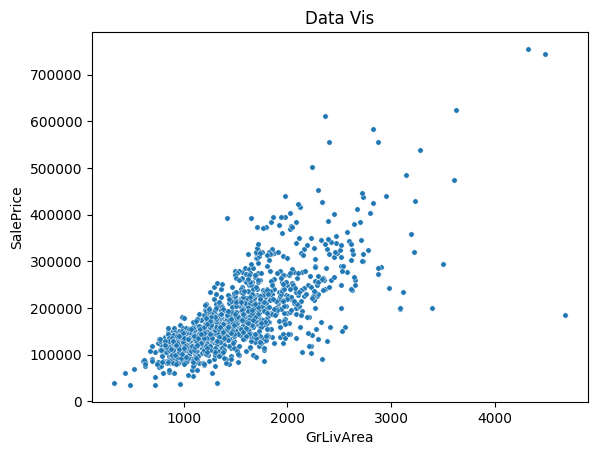

In [ ]:
sns.scatterplot(x=df['GrLivArea'], y=df['SalePrice'], s=15)
plt.title('Data Vis')
plt.show()

#visualizing the data based on GrLivArea vs Sale Price to see if there is something that we can immediately pull out that might suggest the next steps for preprocessing / cleaning.

Looking at the data above, we can see a right skew, a good way to correct this is to run a log on the Sale Price to make the distribution more balanced. But before that lets get rid of the outliers that were mentioned in the data description.

In [ ]:
df[df['GrLivArea'] > 4000][['GrLivArea', 'SalePrice', 'SaleCondition']]

#lets get rid of id 524 because it is a partial sale

,GrLivArea,SalePrice,SaleCondition
Id,,,
524,4676,184750,Partial
692,4316,755000,Normal
1183,4476,745000,Abnorml


In [14]:
df = df.drop(index=524)
print(df.shape)

(1199, 80)


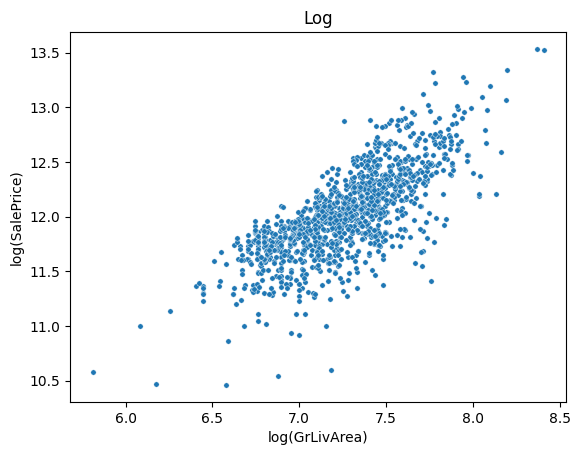

In [ ]:
sns.scatterplot(x=np.log(df['GrLivArea']), y=np.log(df['SalePrice']), s=15)
plt.title('Log')
plt.xlabel('log(GrLivArea)')
plt.ylabel('log(SalePrice)')
plt.show()

#Immediately see that it is far more balanced here, less outliers. better for model training and reduces some of the noise.

Now lets go ahead and tackle missing values as described by the data description

In [37]:
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False)

#Finding missing values and sorting by ascending.

PoolQC          1195
MiscFeature     1152
Alley           1124
Fence            972
MasVnrType       717
FireplaceQu      564
GarageType        67
GarageFinish      67
GarageQual        67
GarageCond        67
BsmtExposure      33
BsmtFinType2      33
BsmtQual          32
BsmtCond          32
BsmtFinType1      32
MasVnrArea         6
dtype: int64

Looking at the data description, for some columns, an N/A value means that the house just doesn't have this feature. Dropping them would be inadequate.

In [ ]:

df['MSSubClass'] = df['MSSubClass'].astype(str)

neighborhood_median = df.groupby('Neighborhood')['LotFrontage'].median()
df['LotFrontage'] = df['LotFrontage'].fillna(df['Neighborhood'].map(neighborhood_median))

#for N/A Values in lot frontage, we are replacing it with the neighborhood median here.

df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])

#for garage year built, we are just going to assume its built in the same year as the house, if there is no garage, we get that signal from other features.


X = df.drop(columns='SalePrice')
y = np.log(df['SalePrice'])

#defining X and Y, with X being all features other than sales price.


#according to data description, this column is actually a string not a number ^

none_cols = [c for c in missing[missing > 0].index if df[c].dtype == 'object']

#Selecting the object datatypes in our cols with missing values >0

zero_cols = ['MasVnrArea']

#according to the data description, for this column, NA actually means 0.

num_cols = [c for c in X.select_dtypes('number').columns if c not in zero_cols]

#Selecting num_cols

cat_cols = [c for c in X.select_dtypes('object').columns if c not in none_cols]

#Selecting cat_cols

In [ ]:
from sklearn.impute import SimpleImputer #According to SKLearn docs, the best way to standardize this fill so I can put it in a pipeline for test data is through the imputer.

#Handled the neighborhood part seperately because we need to use a different approach for that than for the other

imputer = make_column_transformer(
    (SimpleImputer(strategy='constant', fill_value='None'), none_cols), #fills N/A on the none columns with a string 'None'
    (SimpleImputer(strategy='constant', fill_value=0), zero_cols), #fills n/a on the zero_cols with 0
    (SimpleImputer(strategy='median'), num_cols), #fills N/a on the num cols that we didn't already catch with the median of the column
    (SimpleImputer(strategy='most_frequent'), cat_cols), #fills N/A on the cat cols with the most frequent in the data set.
    verbose_feature_names_out=False, # so we can put it in a pipeline later
)

imputer.set_output(transform='pandas')

X_filled = imputer.fit_transform(X)
print(X.shape, X_filled.shape)

(1199, 79) (1199, 79)


In [43]:
print(X_filled.isna().sum().sum())

#shows that we now have 0 N/A values and have handled them accordingly.

0


Now that we have handled the N/A Values, the next step is to handle Ordinal and OHE encoding and categorical/ordinal scaling for the model training.

In [44]:
quality = ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
bsmt_fin = ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ']

#using the data description for these ordinal rankings

ordinal_map = {
    'ExterQual': quality, 'ExterCond': quality, 'BsmtQual': quality, 'BsmtCond': quality,
    'HeatingQC': quality, 'KitchenQual': quality, 'FireplaceQu': quality,
    'GarageQual': quality, 'GarageCond': quality, 'PoolQC': quality,
    'BsmtExposure': ['None', 'No', 'Mn', 'Av', 'Gd'],
    'BsmtFinType1': bsmt_fin, 'BsmtFinType2': bsmt_fin,
    'GarageFinish': ['None', 'Unf', 'RFn', 'Fin'],
    'PavedDrive': ['N', 'P', 'Y'],
    'CentralAir': ['N', 'Y'],
}

#mapping our ordinal rankings to the columns according to our data description here.

ordinal_cols = list(ordinal_map)
none_nominal = [c for c in none_cols if c not in ordinal_cols] #nominal columns where none means that the feature doesn't exist for the house in question
cat_nominal = [c for c in cat_cols if c not in ordinal_cols]


Pipeline

In [49]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler,  FunctionTransformer

In [50]:
log_cols = [c for c in num_cols
            if X[c].nunique() > 50 #greater than 50 unique values
            and X[c].skew() > 0.5 #checks skew
            and (X[c] == 0).mean() < 0.05] #keeps column only if less than 5% of values are 0, so that 0s don't dominate the data

#these are the features we are going to log that are right skewed

scale_cols = [c for c in zero_cols + num_cols if c not in log_cols]

encoder = make_column_transformer(
    (make_pipeline(OrdinalEncoder(categories=list(ordinal_map.values())),
                   StandardScaler()), ordinal_cols),
    (OneHotEncoder(handle_unknown='ignore', sparse_output=False), none_nominal + cat_nominal),
    (StandardScaler(), scale_cols),
    (make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), log_cols), #using log1p so that 0s don't mess up the model
)
#Creating a transfomer for all the encoding steps (OHE + Ordinal + Standard Scaler + log)

preprocessor = make_pipeline(imputer, encoder)


In [51]:
X_ready = preprocessor.fit_transform(X)
print(X.shape, X_ready.shape)
print(np.isnan(X_ready).sum())

(1199, 79) (1199, 245)
0


Final Model

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor, VotingRegressor
from sklearn.linear_model import LassoCV
from sklearn.metrics import root_mean_squared_error

blend = VotingRegressor([
    ('lasso', LassoCV(alphas=np.logspace(-4, -1, 30), max_iter=20000)),
    ('gbr', GradientBoostingRegressor(n_estimators=1500, learning_rate=0.02, max_depth=3, subsample=0.7, max_features=0.3, min_samples_leaf=5,loss='huber', random_state=0)),
])
#Played around with a couple models and loss functions for the gradient boosting regressor and came up with this as the best blend

#According to SKLearn VotingRegressor 50/50 blends these two models, which helps minimize the shortcomings of both (bias vs variability)

final_model = make_pipeline(preprocessor, blend)

# Hold out 20% to check for overfitting
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
final_model.fit(X_train, y_train)
print('Train RMSE:', round(root_mean_squared_error(y_train, final_model.predict(X_train)), 4))
print('Validation RMSE:', round(root_mean_squared_error(y_val, final_model.predict(X_val)), 4))

# Refit on all the training data, then predict test
final_model.fit(X, y)

test = pd.read_csv('regression-for-house-prices/ames/test.csv', index_col='Id')
test['MSSubClass'] = test['MSSubClass'].astype(str)
#Changing MSSubClass to string for the test data
test['LotFrontage'] = test['LotFrontage'].fillna(test['Neighborhood'].map(neighborhood_median))
#filling in the N/A values in lotfrontage for test data with the median for the neighborhood
test['GarageYrBlt'] = test['GarageYrBlt'].fillna(test['YearBuilt'])
#filling in the garage yr built with house yr built for the test data

preds = np.exp(final_model.predict(test))  # back to dollars because we did the log


#Exports
# ---------------------------------------------
submission = pd.read_csv('regression-for-house-prices/ames/sample_soln.csv')
submission['sample_soln'] = preds
submission.to_csv('submission.csv', index=False)

Train RMSE: 0.0707
Validation RMSE: 0.1235
